<a href="https://www.kaggle.com/code/nicapotato/guided-telecom-customer-accounts?scriptVersionId=363172272" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Guided Telecom Customer Accounts
_Contract, fiber, tenure, and charges behind a 7,043-account snapshot_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [alipakzad/telecom-customer-churn](https://www.kaggle.com/datasets/alipakzad/telecom-customer-churn)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***


# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Contract, Product, and Household](#Contract)** <br>
**5. [Tenure and Monthly Charges](#Tenure)** <br>
**6. [Add-ons Among Internet Customers](#Addons)** <br>
**7. [Correlations](#Correlations)** <br>
**8. [Churn Classification](#Classification)** <br>
**9. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
One row is one telecom account: 7,043 customers, with tenure, phone and internet product, add-on flags, contract, payment method, monthly charges, and a Yes/No `Churn` label. About 26.5% have churned (1,869 accounts). The question is which plan and tenure patterns concentrate that risk.

Eleven accounts have tenure 0 and a blank `TotalCharges`. All eleven are still active, mostly on two-year contracts — new sign-ups who have not been billed. Those blanks stay missing. They are not filled with zero or with the monthly price. `TotalCharges` is also close to tenure times the monthly price, so it is a poor standalone churn feature: leavers have not had time to accumulate a bill.


# **2. Setup and Data Peek:** <a id="Setup"></a>


In [1]:
# General
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, recall_score, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
sns.set_palette([
    "#30a2da",
    "#fc4f30",
    "#e5ae38",
    "#6d904f",
    "#8b8b8b",
])
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the account table; `matplotlib` / `seaborn` do the graphics; `scipy` tests the contract association; `sklearn` fits a logistic regression and a random forest on a hold-out. `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series. Tenure and monthly charges are standardized inside the logistic pipeline so their coefficients are per standard deviation; category coefficients are log-odds against the dropped reference level.


In [2]:
# Read and peek at the account snapshot
CSV_BASENAME = "IT_customer_churn.csv"
KAGGLE_SLUG = "alipakzad/telecom-customer-churn"
CONTRACT_ORDER = ["Month-to-month", "One year", "Two year"]
INTERNET_ORDER = ["Fiber optic", "DSL", "No"]
PAY_ORDER = [
    "Electronic check", "Mailed check",
    "Bank transfer (automatic)", "Credit card (automatic)",
]
EXPECTED = [
    "gender", "SeniorCitizen", "Partner", "Dependents", "tenure", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity", "OnlineBackup",
    "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies", "Contract",
    "PaperlessBilling", "PaymentMethod", "MonthlyCharges", "TotalCharges", "Churn",
]


def resolve_csv_path(basename: str = CSV_BASENAME) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for p in kaggle_root.rglob(basename):
            return p
    local_data = Path("data") / basename
    if local_data.exists():
        return local_data
    root = Path(kagglehub.dataset_download(KAGGLE_SLUG))
    p = root / basename
    if not p.exists():
        hits = list(root.rglob(basename))
        assert hits, f"expected {basename} under {root}"
        p = hits[0]
    return p


csv_path = resolve_csv_path()
print("CSV:", csv_path)
df = pd.read_csv(csv_path, low_memory=False)
missing = set(EXPECTED) - set(df.columns)
assert not missing, sorted(missing)
assert df.shape == (7043, 20), df.shape
assert set(df["Churn"]) == {"Yes", "No"}
assert set(df["SeniorCitizen"]) == {0, 1}

# Blank TotalCharges are unbilled new accounts. Leave them missing.
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
blank = df["TotalCharges"].isna()
assert int(blank.sum()) == 11
assert (df.loc[blank, "tenure"] == 0).all()
assert (df.loc[blank, "Churn"] == "No").all()
print(f"Blank TotalCharges: {int(blank.sum())} (tenure 0, all still active — left as missing)")

df["churn"] = (df["Churn"] == "Yes").astype(int)
df["Senior"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
df["Contract"] = pd.Categorical(df["Contract"], CONTRACT_ORDER, ordered=True)
df["InternetService"] = pd.Categorical(df["InternetService"], INTERNET_ORDER, ordered=True)
df["PaymentMethod"] = pd.Categorical(df["PaymentMethod"], PAY_ORDER, ordered=True)
df["tenure_bin"] = pd.cut(
    df["tenure"],
    bins=[-0.1, 6, 12, 24, 48, 72],
    labels=["0–6", "7–12", "13–24", "25–48", "49–72"],
)

print("Dataframe Dimension: {} Rows, {} Columns".format(*df.shape))
print(f"Churn rate: {df['churn'].mean():.3f} ({int(df['churn'].sum())} of {len(df)})")
display(df.dtypes.to_frame("dtype"))
display(df.sample(5, random_state=7))


CSV: /kaggle/input/datasets/alipakzad/telecom-customer-churn/IT_customer_churn.csv
Blank TotalCharges: 11 (tenure 0, all still active — left as missing)
Dataframe Dimension: 7043 Rows, 23 Columns
Churn rate: 0.265 (1869 of 7043)


,dtype
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,category
OnlineSecurity,object
OnlineBackup,object


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,churn,Senior,tenure_bin
6632,Female,0,Yes,No,34,Yes,Yes,DSL,Yes,Yes,No,Yes,No,No,Month-to-month,No,Electronic check,62.65,2274.90,Yes,1,No,25–48
3801,Female,1,No,No,18,Yes,Yes,Fiber optic,No,Yes,No,Yes,No,No,Month-to-month,Yes,Electronic check,85.45,1505.85,Yes,1,Yes,13–24
901,Female,0,No,No,9,Yes,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,No,Credit card (automatic),98.30,923.50,Yes,1,No,7–12
1487,Female,0,No,No,56,Yes,Yes,Fiber optic,No,Yes,Yes,No,Yes,Yes,One year,Yes,Electronic check,106.80,5914.40,No,0,No,49–72
1457,Male,0,Yes,No,42,Yes,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,One year,Yes,Electronic check,108.30,4586.15,No,0,No,25–48


**Code Explanation and Reasoning:** <br>
Shape, the 20-column schema, and the binary churn and senior flags are asserted. `TotalCharges` arrives as text because of the 11 blanks; coercing it to numeric turns those blanks into NaN and leaves every billed account as a float. The assert ties those 11 rows to tenure 0 and `Churn == "No"`, which is the reason they are not imputed.

Contract, internet, and payment are ordered so later heatmaps and boxplots keep a stable axis: month-to-month before term contracts, fiber before DSL before no internet, electronic check before the automatic methods.


In [3]:
unique_count = [
    [c, df[c].nunique(dropna=False), int(df[c].isnull().sum())] for c in df.columns
]
display(
    pd.DataFrame(unique_count, columns=["Column", "Unique", "Null"])
    .sort_values("Unique", ascending=False)
    .reset_index(drop=True)
)
display(df[["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen"]].describe().round(2))


,Column,Unique,Null
0,TotalCharges,6531,11
1,MonthlyCharges,1585,0
2,tenure,73,0
3,tenure_bin,5,0
4,PaymentMethod,4,0
5,MultipleLines,3,0
6,InternetService,3,0
7,Contract,3,0
8,StreamingMovies,3,0
9,StreamingTV,3,0


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen
count,7043.00,7043.00,7032.00,7043.00
mean,32.37,64.76,2283.30,0.16
std,24.56,30.09,2266.77,0.37
min,0.00,18.25,18.80,0.00
25%,9.00,35.50,401.45,0.00
50%,29.00,70.35,1397.48,0.00
75%,55.00,89.85,3794.74,0.00
max,72.00,118.75,8684.80,1.00


**Interpretation** <br>
Most columns are short categories (2 or 3 levels). Tenure runs from 0 to 72 months (median 29). Monthly charges run from about 18 to 119 (median about 70) and are pulled by a cheap no-internet group near 20 and a fiber group near 90. `TotalCharges` is the only column with nulls, and `describe` counts 7,032 billed accounts rather than 7,043. Churn is the minority class at 26.5%, so a classifier that calls everyone a stayer scores about 73.5% accuracy and is still useless for retention.


# **3. Univariate Distributions:** <a id="Univariate"></a>


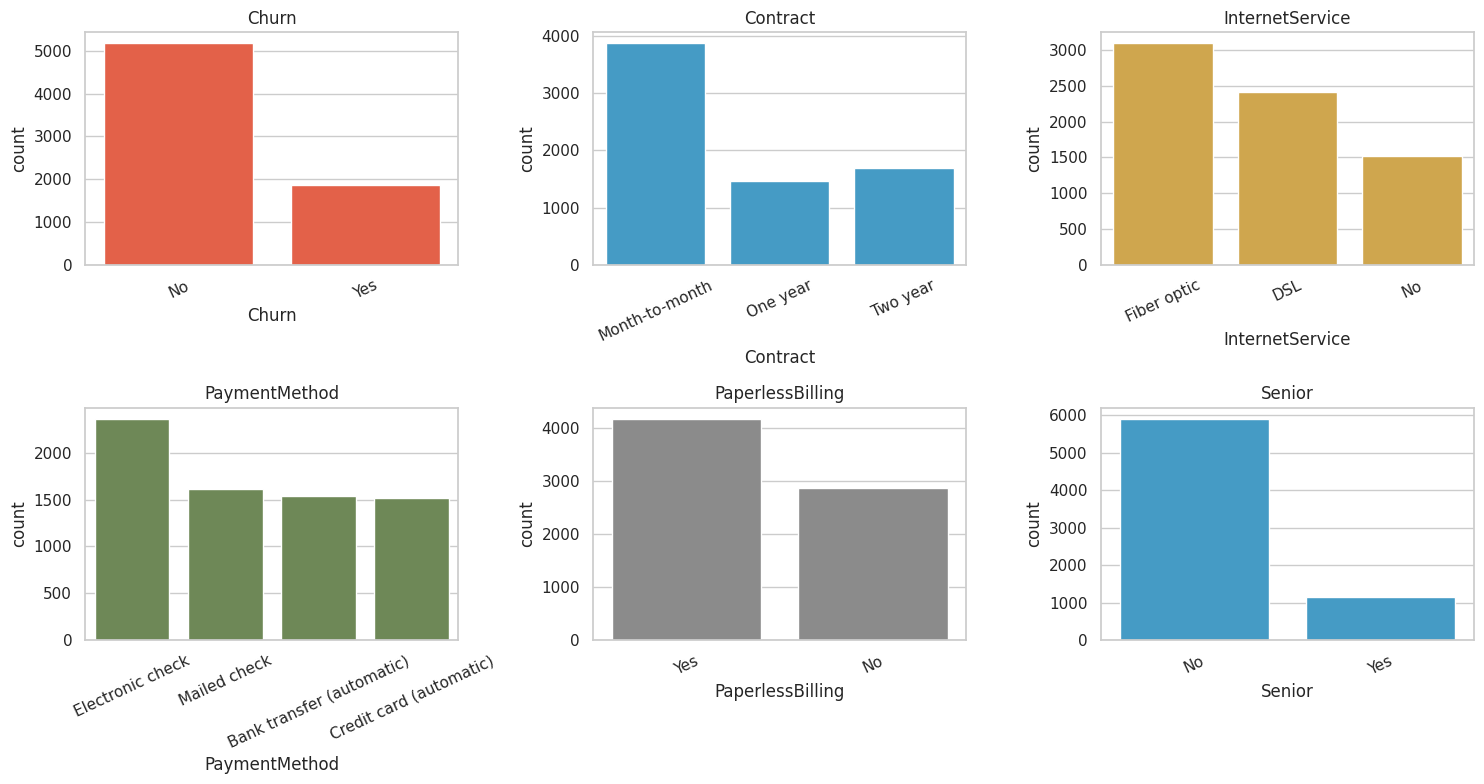

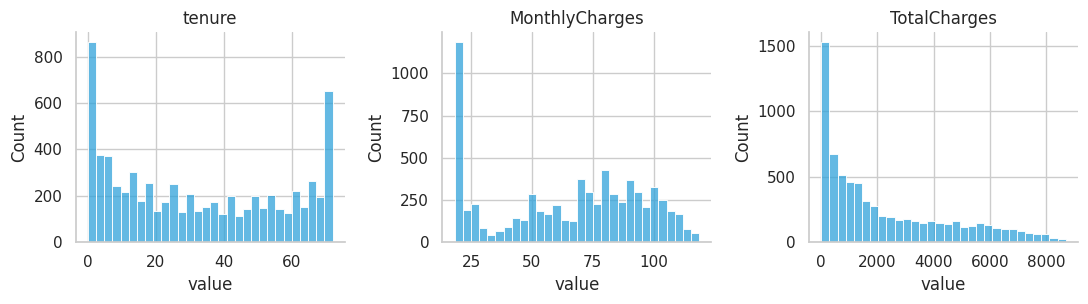

Gender counts: {'Male': 3555, 'Female': 3488}
Partner counts: {'No': 3641, 'Yes': 3402}
Dependents counts: {'No': 4933, 'Yes': 2110}
Phone service counts: {'Yes': 6361, 'No': 682}


In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
axes = axes.ravel()
for ax, col, color in [
    (axes[0], "Churn", "#fc4f30"),
    (axes[1], "Contract", "#30a2da"),
    (axes[2], "InternetService", "#e5ae38"),
    (axes[3], "PaymentMethod", "#6d904f"),
    (axes[4], "PaperlessBilling", "#8b8b8b"),
    (axes[5], "Senior", "#30a2da"),
]:
    sns.countplot(data=df, x=col, ax=ax, color=color)
    ax.set_title(col)
    ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

melt = df[["tenure", "MonthlyCharges", "TotalCharges"]].melt(
    var_name="feature", value_name="value",
)
g = sns.FacetGrid(
    melt, col="feature", col_wrap=3, sharex=False, sharey=False, height=3.2, aspect=1.15,
)
g.map_dataframe(sns.histplot, x="value", bins=30, color="#30a2da")
g.set_titles("{col_name}")
plt.show()

print("Gender counts:", df["gender"].value_counts().to_dict())
print("Partner counts:", df["Partner"].value_counts().to_dict())
print("Dependents counts:", df["Dependents"].value_counts().to_dict())
print("Phone service counts:", df["PhoneService"].value_counts().to_dict())


**Interpretation** <br>
Month-to-month is the modal contract, fiber is the modal internet product, and electronic check is the modal payment method. Seniors are about one in six accounts. Gender is balanced; dependents are the minority household flag; most accounts have a phone line. Tenure piles up at the first months and again near 72 (people who have stayed for the whole window the table can see). Monthly charges are bimodal. Total charges rise smoothly because they accumulate — the shape to keep in mind when that column later correlates with tenure rather than with risk.


# **4. Contract, Product, and Household:** <a id="Contract"></a>


Chi-square Contract × Churn: chi2=1184.6, dof=2, p=5.863e-258


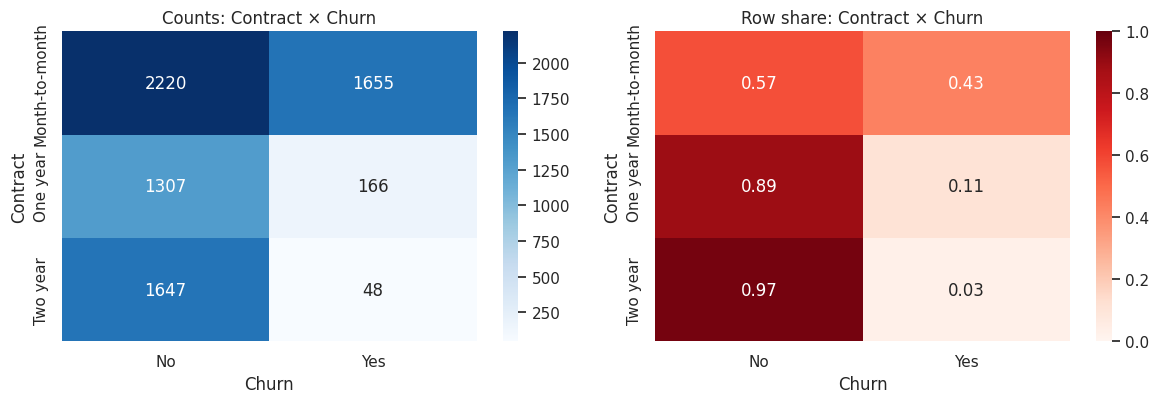

Churn rate, Contract × Internet:


InternetService,Fiber optic,DSL,No
Contract,,,
Month-to-month,54.6%,32.2%,18.9%
One year,19.3%,9.3%,2.5%
Two year,7.2%,1.9%,0.8%


Cell counts:


InternetService,Fiber optic,DSL,No
Contract,,,
Month-to-month,2128,1223,524
One year,539,570,364
Two year,429,628,638


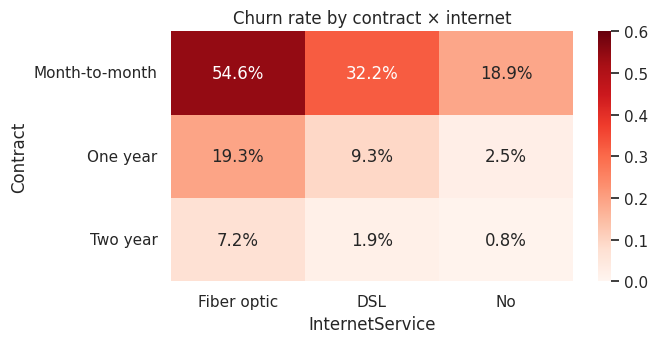

Churn rate, Payment × Contract:


Contract,Month-to-month,One year,Two year
PaymentMethod,,,
Electronic check,53.7%,18.4%,7.7%
Mailed check,31.6%,6.8%,0.8%
Bank transfer (automatic),34.1%,9.7%,3.4%
Credit card (automatic),32.8%,10.3%,2.2%


Raw churn rate by household / account flag:


,flag,level,n,churn_rate
0,gender,Female,3488,26.9%
1,gender,Male,3555,26.2%
2,Senior,No,5901,23.6%
3,Senior,Yes,1142,41.7%
4,Partner,No,3641,33.0%
5,Partner,Yes,3402,19.7%
6,Dependents,No,4933,31.3%
7,Dependents,Yes,2110,15.5%
8,PaperlessBilling,No,2872,16.3%
9,PaperlessBilling,Yes,4171,33.6%


In [5]:
contract_n = pd.crosstab(df["Contract"], df["Churn"]).reindex(
    index=CONTRACT_ORDER, columns=["No", "Yes"],
)
contract_p = pd.crosstab(df["Contract"], df["Churn"], normalize="index").reindex(
    index=CONTRACT_ORDER, columns=["No", "Yes"],
)
chi2, p_chi, dof, _ = stats.chi2_contingency(contract_n)
print(f"Chi-square Contract × Churn: chi2={chi2:.1f}, dof={dof}, p={p_chi:.3e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.heatmap(contract_n, annot=True, fmt="d", cmap="Blues", ax=axes[0])
axes[0].set_title("Counts: Contract × Churn")
sns.heatmap(contract_p, annot=True, fmt=".2f", cmap="Reds", vmin=0, vmax=1, ax=axes[1])
axes[1].set_title("Row share: Contract × Churn")
plt.tight_layout()
plt.show()

rate = df.pivot_table(
    index="Contract", columns="InternetService", values="churn",
    aggfunc="mean", observed=False,
).reindex(index=CONTRACT_ORDER, columns=INTERNET_ORDER)
n_cell = pd.crosstab(df["Contract"], df["InternetService"]).reindex(
    index=CONTRACT_ORDER, columns=INTERNET_ORDER,
)
print("Churn rate, Contract × Internet:")
display(rate.style.format("{:.1%}").background_gradient(cmap="Reds", axis=None))
print("Cell counts:")
display(n_cell)
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.heatmap(rate, annot=True, fmt=".1%", cmap="Reds", ax=ax, vmin=0, vmax=0.6)
ax.set_title("Churn rate by contract × internet")
plt.tight_layout()
plt.show()

pay_rate = df.pivot_table(
    index="PaymentMethod", columns="Contract", values="churn",
    aggfunc="mean", observed=False,
).reindex(index=PAY_ORDER, columns=CONTRACT_ORDER)
print("Churn rate, Payment × Contract:")
display(pay_rate.style.format("{:.1%}").background_gradient(cmap="Reds", axis=None))

rows = []
for col in ["gender", "Senior", "Partner", "Dependents", "PaperlessBilling", "PhoneService"]:
    for level, sub in df.groupby(col, observed=True):
        rows.append({
            "flag": col, "level": str(level), "n": int(len(sub)),
            "churn_rate": float(sub["churn"].mean()),
        })
household = pd.DataFrame(rows)
print("Raw churn rate by household / account flag:")
display(
    household.style.format({"churn_rate": "{:.1%}"})
    .background_gradient(subset=["churn_rate"], cmap="Reds")
)


**Interpretation** <br>
Contract is the sharp cut. Month-to-month accounts churn at 42.7%, one-year at 11.3%, two-year at 2.8%. A chi-square on that table is enormous — this is not a small-sample wobble. Internet stacks on top: fiber churns at 41.9%, DSL at 19.0%, and no-internet at 7.4%. The cell that matters is month-to-month fiber, 54.6% churn on 2,128 accounts. Two-year DSL and two-year no-internet are almost quiet.

Electronic check is the risky tender (about 45% overall) and it remains the high cell inside month-to-month (about 54%). Gender and phone service are flat, near the 26.5% base rate. Seniors (about 42%), customers without a partner or dependents, and paperless billers show higher raw rates. Those household gaps are real as descriptions and easy to over-read: seniors and paperless billing also concentrate on month-to-month. Section 8 asks which of them still move the log-odds after contract and fiber are in the model. `MultipleLines` is left out of this table because its third level, "No phone service", only repeats `PhoneService == "No"`.


# **5. Tenure and Monthly Charges:** <a id="Tenure"></a>


Churn rate by tenure bin:


,churn_rate,n
tenure_bin,,
0–6,52.9%,1481
7–12,35.9%,705
13–24,28.7%,1024
25–48,20.4%,1594
49–72,9.5%,2239


Median tenure and monthly charges by churn:


,tenure,MonthlyCharges
Churn,,
No,38.0,64.4
Yes,10.0,79.6


Median monthly charges by internet × churn:


Churn,No,Yes
InternetService,,
Fiber optic,94.8,87.6
DSL,59.8,49.2
No,20.2,20.0


Median tenure by contract × churn:


Churn,No,Yes
Contract,,
Month-to-month,16.0,7.0
One year,43.0,48.0
Two year,64.0,65.5


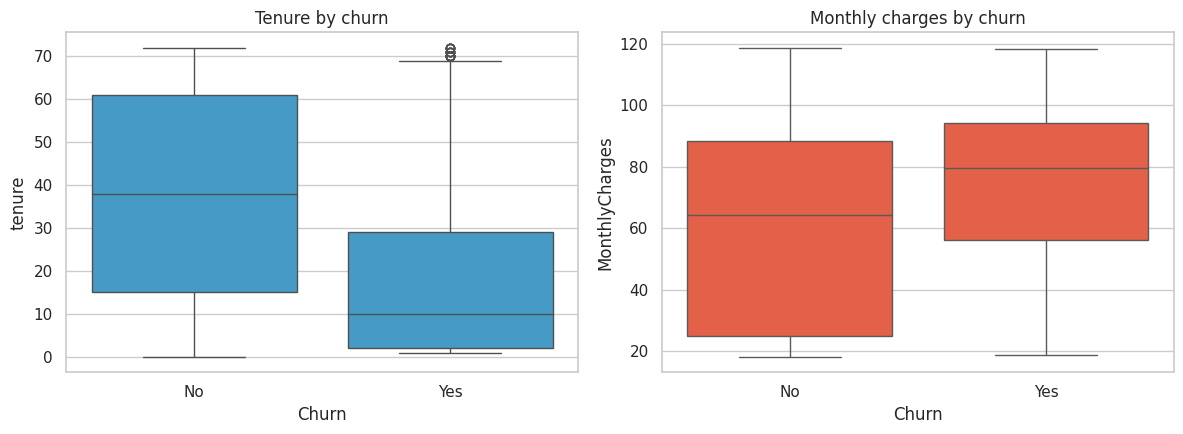

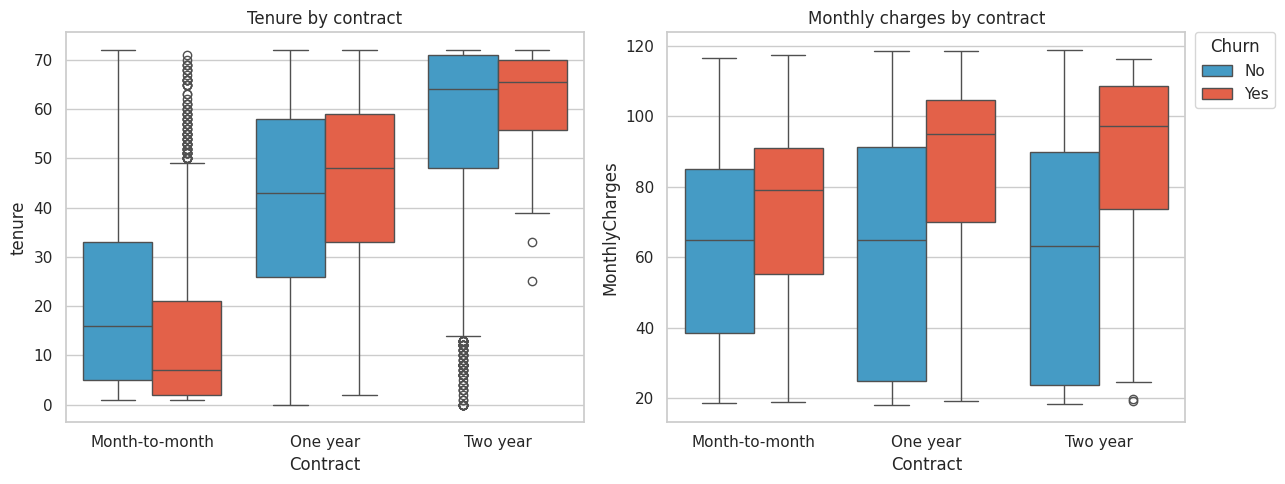

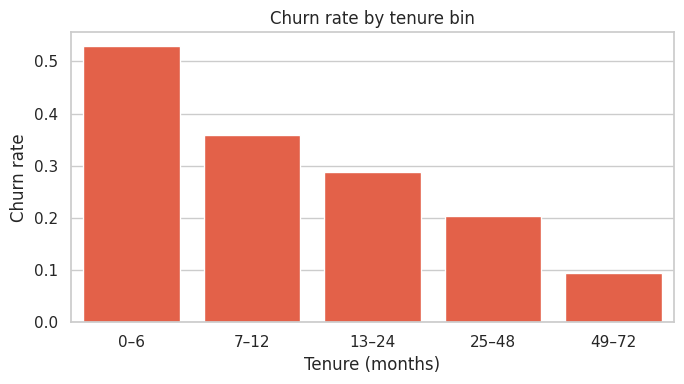

In [6]:
bin_rate = df.groupby("tenure_bin", observed=True)["churn"].agg(["mean", "size"])
bin_rate = bin_rate.rename(columns={"mean": "churn_rate", "size": "n"})
print("Churn rate by tenure bin:")
display(bin_rate.style.format({"churn_rate": "{:.1%}"}).background_gradient(
    subset=["churn_rate"], cmap="Reds",
))
print("Median tenure and monthly charges by churn:")
display(df.groupby("Churn")[["tenure", "MonthlyCharges"]].median().round(1))
print("Median monthly charges by internet × churn:")
display(
    df.groupby(["InternetService", "Churn"], observed=True)["MonthlyCharges"]
    .median().unstack().reindex(INTERNET_ORDER).round(1)
)
print("Median tenure by contract × churn:")
display(
    df.groupby(["Contract", "Churn"], observed=True)["tenure"]
    .median().unstack().reindex(CONTRACT_ORDER).round(1)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=df, x="Churn", y="tenure", order=["No", "Yes"], color="#30a2da", ax=axes[0])
axes[0].set_title("Tenure by churn")
sns.boxplot(
    data=df, x="Churn", y="MonthlyCharges", order=["No", "Yes"], color="#fc4f30", ax=axes[1],
)
axes[1].set_title("Monthly charges by churn")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(
    data=df, x="Contract", y="tenure", hue="Churn",
    order=CONTRACT_ORDER, hue_order=["No", "Yes"], ax=axes[0],
)
sns.boxplot(
    data=df, x="Contract", y="MonthlyCharges", hue="Churn",
    order=CONTRACT_ORDER, hue_order=["No", "Yes"], ax=axes[1],
)
axes[0].legend_.remove()
axes[1].legend(title="Churn", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
axes[0].set_title("Tenure by contract")
axes[1].set_title("Monthly charges by contract")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=bin_rate.reset_index(), x="tenure_bin", y="churn_rate", color="#fc4f30", ax=ax,
)
ax.set_title("Churn rate by tenure bin")
ax.set_ylabel("Churn rate")
ax.set_xlabel("Tenure (months)")
plt.tight_layout()
plt.show()


**Interpretation** <br>
Churners have a median tenure of 10 months versus 38 for stayers, and a higher median monthly charge (about 80 versus 64). The charge gap is mostly mix. Inside DSL, leavers are on the cheaper plans (median about 49 versus 60); inside fiber, leavers are also slightly cheaper (about 88 versus 95). Fiber simply costs more, and fiber customers leave more often, so the pooled median makes price look like the risk.

Tenure tells a cleaner story, and it is concentrated in month-to-month. The first six months churn at about 53%, then the rate steps down to about 10% after four years. Inside one-year and two-year contracts, leavers and stayers have similar median tenure. Early exit from a flexible contract is the pattern; a long tenure on a term contract is mostly the people who already signed the term.


# **6. Add-ons Among Internet Customers:** <a id="Addons"></a>


Internet customers: 5517 of 7043
Churn rate by add-on (internet customers only):


level,No,Yes
addon,,
DeviceProtection,39.1%,22.5%
OnlineBackup,39.9%,21.5%
OnlineSecurity,41.8%,14.6%
StreamingMovies,33.7%,29.9%
StreamingTV,33.5%,30.1%
TechSupport,41.6%,15.2%


Counts:


level,No,Yes
addon,,
DeviceProtection,3095,2422
OnlineBackup,3088,2429
OnlineSecurity,3498,2019
StreamingMovies,2785,2732
StreamingTV,2810,2707
TechSupport,3473,2044


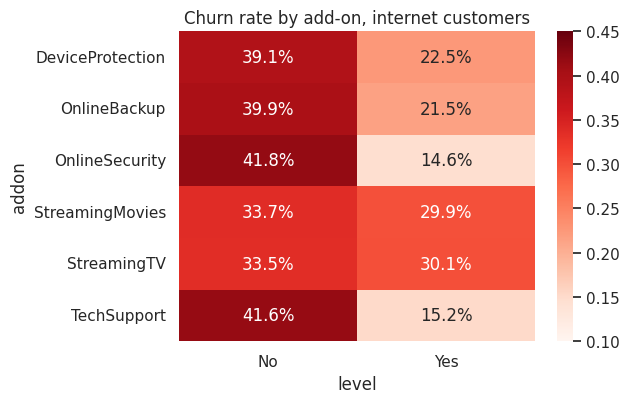

In [7]:
# "No internet service" on an add-on column repeats InternetService == "No".
# Restricting to internet customers makes "No" mean the add-on was declined.
addon_cols = [
    "OnlineSecurity", "OnlineBackup", "DeviceProtection",
    "TechSupport", "StreamingTV", "StreamingMovies",
]
inet = df[df["InternetService"] != "No"].copy()
for col in addon_cols:
    assert set(inet[col].unique()) <= {"Yes", "No"}, col

rows = []
for col in addon_cols:
    for level, sub in inet.groupby(col):
        rows.append({
            "addon": col, "level": level, "n": int(len(sub)),
            "churn_rate": float(sub["churn"].mean()),
        })
addon_tbl = pd.DataFrame(rows)
addon_rate = addon_tbl.pivot(index="addon", columns="level", values="churn_rate")[["No", "Yes"]]
addon_n = addon_tbl.pivot(index="addon", columns="level", values="n")[["No", "Yes"]]
print(f"Internet customers: {len(inet)} of {len(df)}")
print("Churn rate by add-on (internet customers only):")
display(addon_rate.style.format("{:.1%}").background_gradient(cmap="Reds", axis=None))
print("Counts:")
display(addon_n.astype(int))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
sns.heatmap(addon_rate, annot=True, fmt=".1%", cmap="Reds", ax=ax, vmin=0.1, vmax=0.45)
ax.set_title("Churn rate by add-on, internet customers")
plt.tight_layout()
plt.show()


**Interpretation** <br>
Among people who have an internet line, declining online security or tech support lines up with churn near 42%, while taking either one lines up with churn near 15%. Backup and device protection sit in between. Streaming TV and streaming movies barely move (both sides near 30%). Protection add-ons mark the stickier internet customers; entertainment add-ons do not. This comparison is only meaningful inside the internet base. Pooling in the "No internet service" level would credit "no internet" — already a low-churn group — to the add-on column.


# **7. Correlations:** <a id="Correlations"></a>


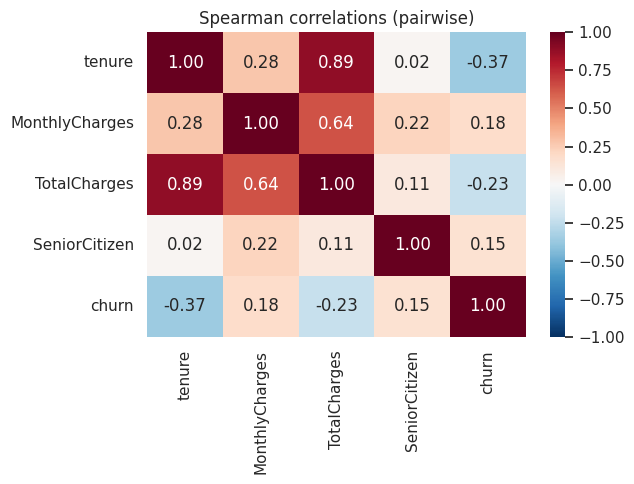

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,churn
tenure,1.000,0.276,0.889,0.019,-0.367
MonthlyCharges,0.276,1.000,0.638,0.221,0.185
TotalCharges,0.889,0.638,1.000,0.107,-0.232
SeniorCitizen,0.019,0.221,0.107,1.000,0.151
churn,-0.367,0.185,-0.232,0.151,1.000


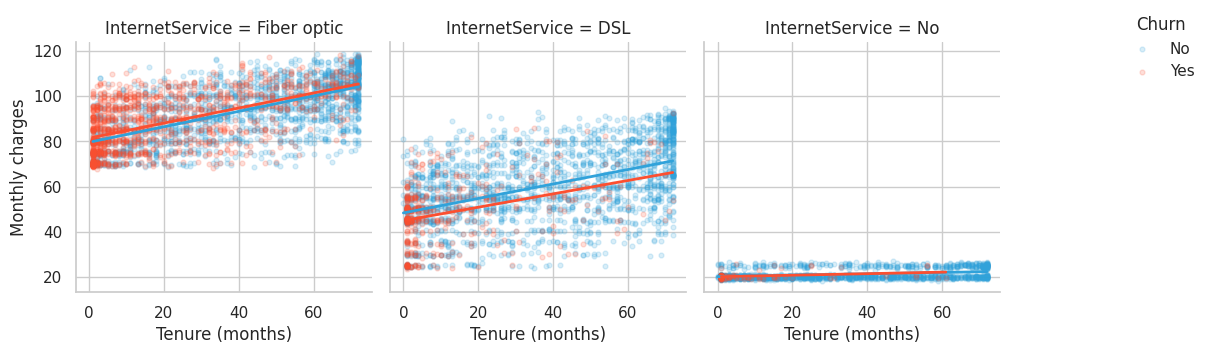

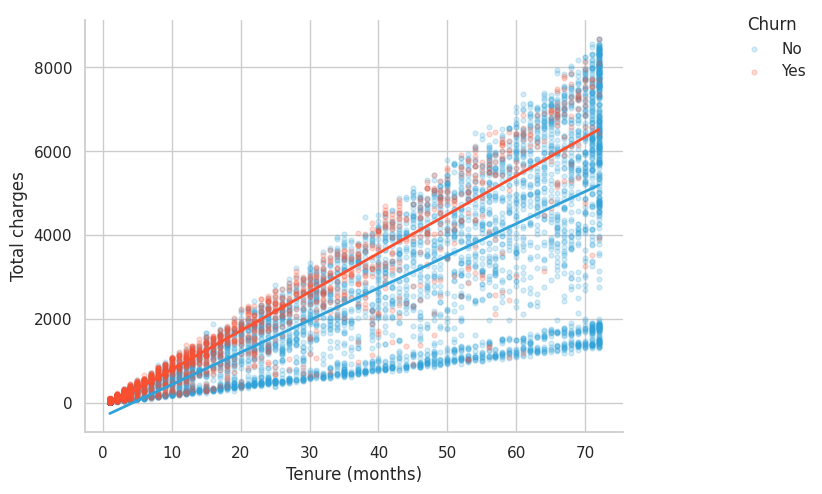

Billed accounts in the total-charges plot: 7032


In [8]:
# Pairwise deletion drops the 11 blank TotalCharges from pairs that use that column only.
corr_cols = ["tenure", "MonthlyCharges", "TotalCharges", "SeniorCitizen", "churn"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Spearman correlations (pairwise)")
plt.tight_layout()
plt.show()
display(corr.round(3))

g = sns.lmplot(
    data=df, x="tenure", y="MonthlyCharges", hue="Churn", hue_order=["No", "Yes"],
    col="InternetService", col_order=INTERNET_ORDER,
    height=3.6, aspect=0.95, ci=None,
    scatter_kws={"alpha": 0.18, "s": 12},
    line_kws={"lw": 2},
)
g.set_axis_labels("Tenure (months)", "Monthly charges")
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Churn", frameon=False)
plt.show()

billed = df.dropna(subset=["TotalCharges"])
g = sns.lmplot(
    data=billed, x="tenure", y="TotalCharges", hue="Churn", hue_order=["No", "Yes"],
    height=5, aspect=1.3, ci=None,
    scatter_kws={"alpha": 0.2, "s": 12},
    line_kws={"lw": 2},
)
g.set_axis_labels("Tenure (months)", "Total charges")
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Churn", frameon=False)
plt.show()
print("Billed accounts in the total-charges plot:", len(billed))


**Interpretation** <br>
Tenure correlates about −0.37 with churn; monthly charges about +0.18; total charges about −0.23. Total charges correlate about 0.89 with tenure (Spearman), which is why a model that includes both will treat total charges as accumulated tenure. The faceted lines show monthly price sitting in bands by product — fiber high, DSL mid, no-internet low — and not climbing with tenure. Churners crowd the short-tenure end of each band. The total-charges scatter is the accumulation line: longer tenure, larger lifetime bill, with leavers stacked on the left.


# **8. Churn Classification:** <a id="Classification"></a>


Majority-class baseline accuracy: 0.735 (test n = 1761)
Logistic hold-out accuracy 0.806 | ROC AUC 0.850 | recall of churners 0.531
Reference Contract = Month-to-month
Reference InternetService = DSL
Reference PaymentMethod = Bank transfer (automatic)
Reference Senior = No
Reference PaperlessBilling = No
RF hold-out accuracy 0.809 | ROC AUC 0.847 | recall of churners 0.548


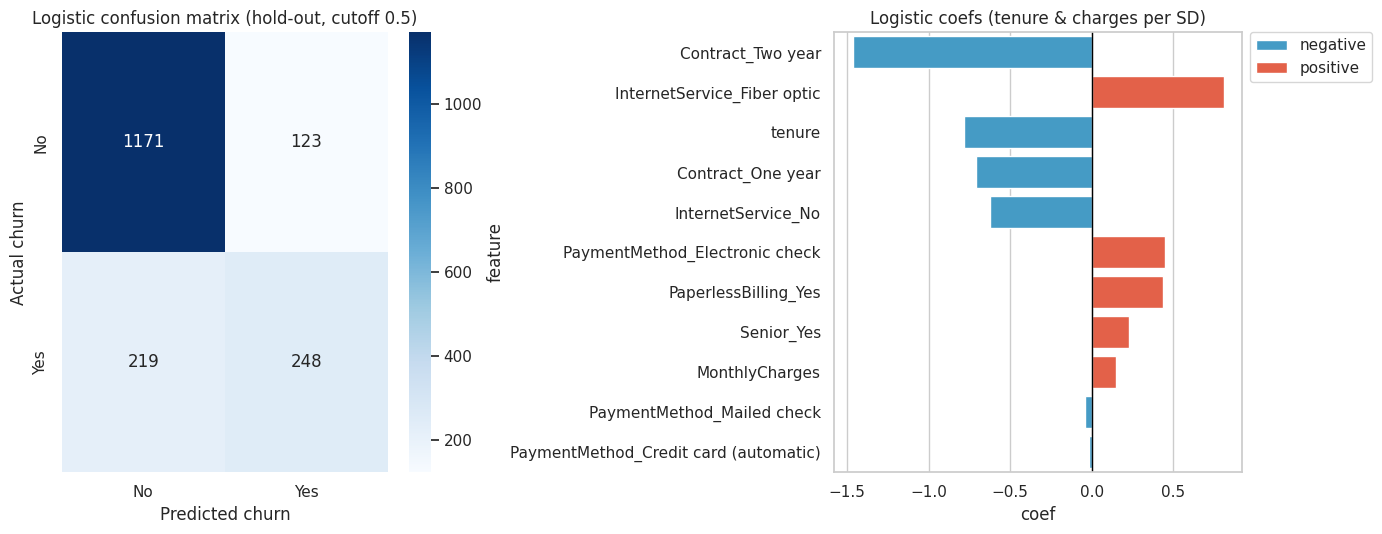

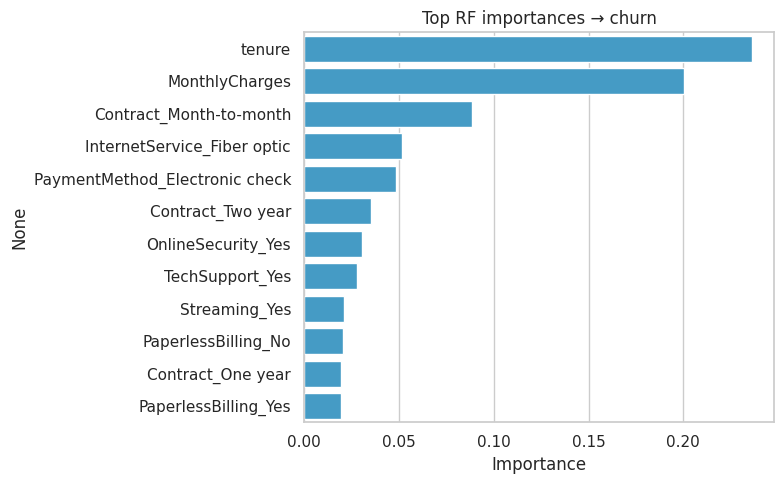

,logit_coef
Contract_Two year,-1.466
InternetService_Fiber optic,0.809
tenure,-0.783
Contract_One year,-0.708
InternetService_No,-0.625
PaymentMethod_Electronic check,0.447
PaperlessBilling_Yes,0.437
Senior_Yes,0.231
MonthlyCharges,0.147
PaymentMethod_Mailed check,-0.041


,rf_importance
tenure,0.236
MonthlyCharges,0.200
Contract_Month-to-month,0.089
InternetService_Fiber optic,0.052
PaymentMethod_Electronic check,0.049
Contract_Two year,0.035
OnlineSecurity_Yes,0.031
TechSupport_Yes,0.028
Streaming_Yes,0.021
PaperlessBilling_No,0.021


In [9]:
# Logistic uses the plan and the two continuous drivers. Add-on Yes-flags go to the forest
# so "no internet" is carried once, by InternetService, not repeated as a third add-on level.
num = ["tenure", "MonthlyCharges"]
cat = ["Contract", "InternetService", "PaymentMethod", "Senior", "PaperlessBilling"]
X = df[num + cat]
y = df["churn"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=7, stratify=y,
)
pre = ColumnTransformer([
    ("num", StandardScaler(), num),
    ("cat", OneHotEncoder(drop="first"), cat),
])
logit = Pipeline([("pre", pre), ("lr", LogisticRegression(max_iter=1000))])
logit.fit(X_train, y_train)
proba = logit.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
baseline = float((y_test == 0).mean())
print(f"Majority-class baseline accuracy: {baseline:.3f} (test n = {len(y_test)})")
print(
    f"Logistic hold-out accuracy {accuracy_score(y_test, pred):.3f} | "
    f"ROC AUC {roc_auc_score(y_test, proba):.3f} | "
    f"recall of churners {recall_score(y_test, pred):.3f}"
)
encoder = logit.named_steps["pre"].named_transformers_["cat"]
for col, levels in zip(cat, encoder.categories_):
    print(f"Reference {col} = {levels[0]}")

names = num + list(encoder.get_feature_names_out(cat))
coef = pd.Series(logit.named_steps["lr"].coef_[0], index=names)
coef_sorted = coef.reindex(coef.abs().sort_values(ascending=False).index)

df["TechSupport_Yes"] = (df["TechSupport"] == "Yes").astype(int)
df["OnlineSecurity_Yes"] = (df["OnlineSecurity"] == "Yes").astype(int)
df["Streaming_Yes"] = (
    (df["StreamingTV"] == "Yes") | (df["StreamingMovies"] == "Yes")
).astype(int)
num_rf = num + ["TechSupport_Yes", "OnlineSecurity_Yes", "Streaming_Yes"]
cat_rf = cat + ["Partner", "Dependents", "gender"]
X_rf = df[num_rf + cat_rf]
Xtr_rf, Xte_rf, ytr_rf, yte_rf = train_test_split(
    X_rf, y, test_size=0.25, random_state=7, stratify=y,
)
rf_pipe = Pipeline([
    ("pre", ColumnTransformer([
        ("num", "passthrough", num_rf),
        ("cat", OneHotEncoder(), cat_rf),
    ])),
    ("rf", RandomForestClassifier(
        n_estimators=300, max_depth=12, random_state=7, n_jobs=-1,
    )),
])
rf_pipe.fit(Xtr_rf, ytr_rf)
rf_proba = rf_pipe.predict_proba(Xte_rf)[:, 1]
rf_pred = (rf_proba >= 0.5).astype(int)
print(
    f"RF hold-out accuracy {accuracy_score(yte_rf, rf_pred):.3f} | "
    f"ROC AUC {roc_auc_score(yte_rf, rf_proba):.3f} | "
    f"recall of churners {recall_score(yte_rf, rf_pred):.3f}"
)
rf_names = num_rf + list(
    rf_pipe.named_steps["pre"].named_transformers_["cat"].get_feature_names_out(cat_rf)
)
imp = pd.Series(rf_pipe.named_steps["rf"].feature_importances_, index=rf_names)
imp = imp.sort_values(ascending=False).head(12)

cm = confusion_matrix(y_test, pred, labels=[0, 1])
coef_plot = coef_sorted.rename("coef").rename_axis("feature").reset_index()
coef_plot["sign"] = np.where(coef_plot["coef"] >= 0, "positive", "negative")
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["No", "Yes"], yticklabels=["No", "Yes"], ax=axes[0],
)
axes[0].set_xlabel("Predicted churn")
axes[0].set_ylabel("Actual churn")
axes[0].set_title("Logistic confusion matrix (hold-out, cutoff 0.5)")
sns.barplot(
    data=coef_plot, x="coef", y="feature", hue="sign", dodge=False,
    palette={"positive": "#fc4f30", "negative": "#30a2da"}, ax=axes[1],
)
axes[1].axvline(0, color="black", lw=1)
axes[1].legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left", borderaxespad=0)
axes[1].set_title("Logistic coefs (tenure & charges per SD)")
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(x=imp.values, y=imp.index, color="#30a2da", ax=ax)
ax.set_title("Top RF importances → churn")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()
display(coef_sorted.round(3).rename("logit_coef").to_frame())
display(imp.round(3).rename("rf_importance").to_frame())


**Interpretation** <br>
Both models clear the 0.735 majority baseline, at about 0.81 hold-out accuracy and about 0.85 ROC AUC. At a 0.5 cutoff the logistic model recalls only about half of churners (0.53): accuracy looks calm because stayers are easy to call correctly. A retention offer would move that cutoff.

On the logistic scale, a two-year contract (versus month-to-month) is the strongest protective coefficient, then tenure. Fiber (versus DSL) is the strongest risk coefficient; no-internet is protective; electronic check and paperless billing stay positive after those controls, so they are not only proxies for the contract. Senior stays a smaller positive. Monthly charges, once fiber is in the model, are a modest per-SD shift — consistent with the within-product medians, where leavers were not on the expensive plans. The forest, which also sees security, tech support, streaming, partner, dependents, and gender, ranks tenure and monthly charges first, then month-to-month and fiber. Security and tech support appear; streaming, gender, partner, and dependents do not lead. Importances are a ranking of what the forest used on this split, not a causal order.


# **9. What It Means — Working Synthesis:** <a id="Synthesis"></a>

**What the table is:** <br>
A 7,043-account telecom snapshot with service flags, tenure, monthly charges, and a binary churn label. 1,869 accounts (26.5%) have churned.

**Working takeaways:** <br>
- Churn is a contract and product-mix pattern. Month-to-month accounts churn at 42.7%, one-year at 11.3%, two-year at 2.8%. Fiber churns at 41.9% versus 19.0% on DSL and 7.4% with no internet. Month-to-month fiber is the cell that dominates the count: 54.6% of 2,128 accounts.
- Tenure is short for churners (median 10 months versus 38). The first six months churn at about 53%, and the rate falls to about 10% past four years. Inside term contracts, leavers and stayers have similar tenure — the tenure gap is early month-to-month exit.
- The higher monthly bill among churners (median about 80 versus 64) is largely a fiber mix effect. Within DSL and within fiber, leavers are not on the more expensive plans. Electronic check (about 45% churn) and declined security or tech support mark the same flexible fiber base. Streaming does not separate churn. Gender and phone service are flat.
- Partner, dependents, and paperless billing show raw rate gaps that mostly travel with the contract. After contract and fiber are controlled, paperless billing and senior status still shift logistic log-odds; partner and gender do not lead the forest.
- Eleven tenure-0 accounts have blank `TotalCharges`, all still active. Leave them missing. Total charges accumulate with tenure and trend the "wrong" way for a risk feature because leavers have not built a bill.
- Hold-out logistic regression and a random forest both land near 0.81 accuracy and 0.85 AUC against a 0.735 majority baseline. At 0.5, recall of churners is only about half. The logistic leaders are two-year contract (protective), fiber (risk), and tenure (protective).

**Open follow-ups:** <br>
- Choose the score cutoff for recall, not for accuracy — a save offer cares about catching leavers.
- Plot churn by tenure month inside month-to-month fiber only, so the early-life hazard is not averaged with term contracts.
- Keep "no internet" out of the add-on dummies so a support offer is not credited for customers who have no internet line.
- A survival model on tenure, with churn as the event, matches the snapshot better than a single yes/no cut.
